# Wolf–elk introduction experiments

This notebook uses Norman's Beddington–DeAngelis wolf–elk equations with gradual farmer and hunter introductions. Wolf predation accounts for handling time and interference among wolves. Farmer pressure lowers elk carrying capacity and removes wolves; hunter pressure removes elk. Parameters are illustrative, not calibrated.

Edit the settings cell and rerun the notebook to compare scenarios, introduction shapes, and initial populations. State order is `(elk, wolves)`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynamic_introductions import (
    MODEL_SOURCE, WOLF_ELK_DEFAULTS, SHAPES,
    ramp, pressures, simulate,
)
print('Model source:', MODEL_SOURCE)
print('Base parameters:', WOLF_ELK_DEFAULTS)

Model source: Repository ecosystem_ode.py
Base parameters: {'r_E': 0.4, 'K': 1200.0, 'alpha_FE': 10.0, 'a': 0.001, 'eta': 0.25, 'd_W': 0.08, 'F': 6.0, 'H': 4.0, 'c_HE': 0.003, 'c_FW': 0.004}


## Settings

All populations are listed as `(elk, wolves)`. Farmer and hunter maxima must be nonnegative, and the maximum farmer pressure must leave a positive effective elk carrying capacity.

In [2]:
START = 10.0
DURATION = 35.0
T_END = 240.0
MAX_FARMERS = 40.0
MAX_HUNTERS = 25.0
INITIAL_STATES = [(200, 25), (400, 80), (600, 25),
                   (650, 110), (850, 50), (1050, 120)]
SETTINGS = dict(start=START, duration=DURATION,
                max_farmers=MAX_FARMERS, max_hunters=MAX_HUNTERS)
assert WOLF_ELK_DEFAULTS['K'] - WOLF_ELK_DEFAULTS['alpha_FE'] * MAX_FARMERS > 0

## Introduction shapes

Each schedule rises from zero to full pressure between `START` and `START + DURATION`.

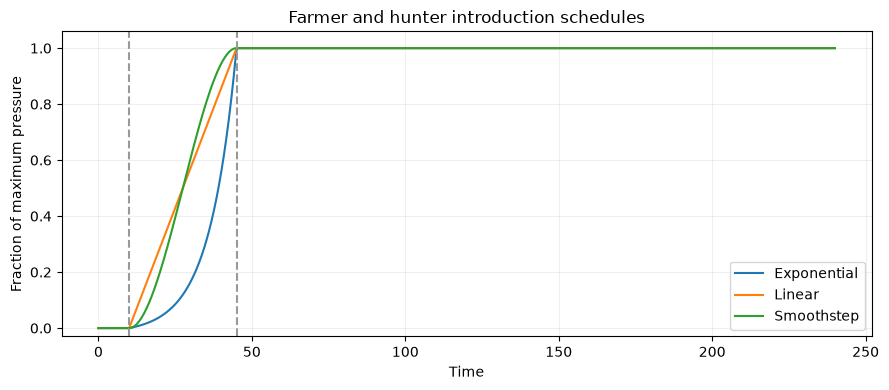

In [3]:
times = np.linspace(0, T_END, 600)
fig, ax = plt.subplots(figsize=(9, 4))
for shape in SHAPES:
    ax.plot(times, ramp(times, shape, START, DURATION), label=shape.title())
ax.axvline(START, color='0.6', ls='--')
ax.axvline(START + DURATION, color='0.6', ls='--')
ax.set(xlabel='Time', ylabel='Fraction of maximum pressure',
       title='Farmer and hunter introduction schedules', ylim=(-0.03, 1.06))
ax.grid(alpha=.2); ax.legend(); fig.tight_layout()

## Wolf versus elk

Each panel compares starting populations under one intervention and introduction shape. The gray dashed curves show the matching no-pressure control.

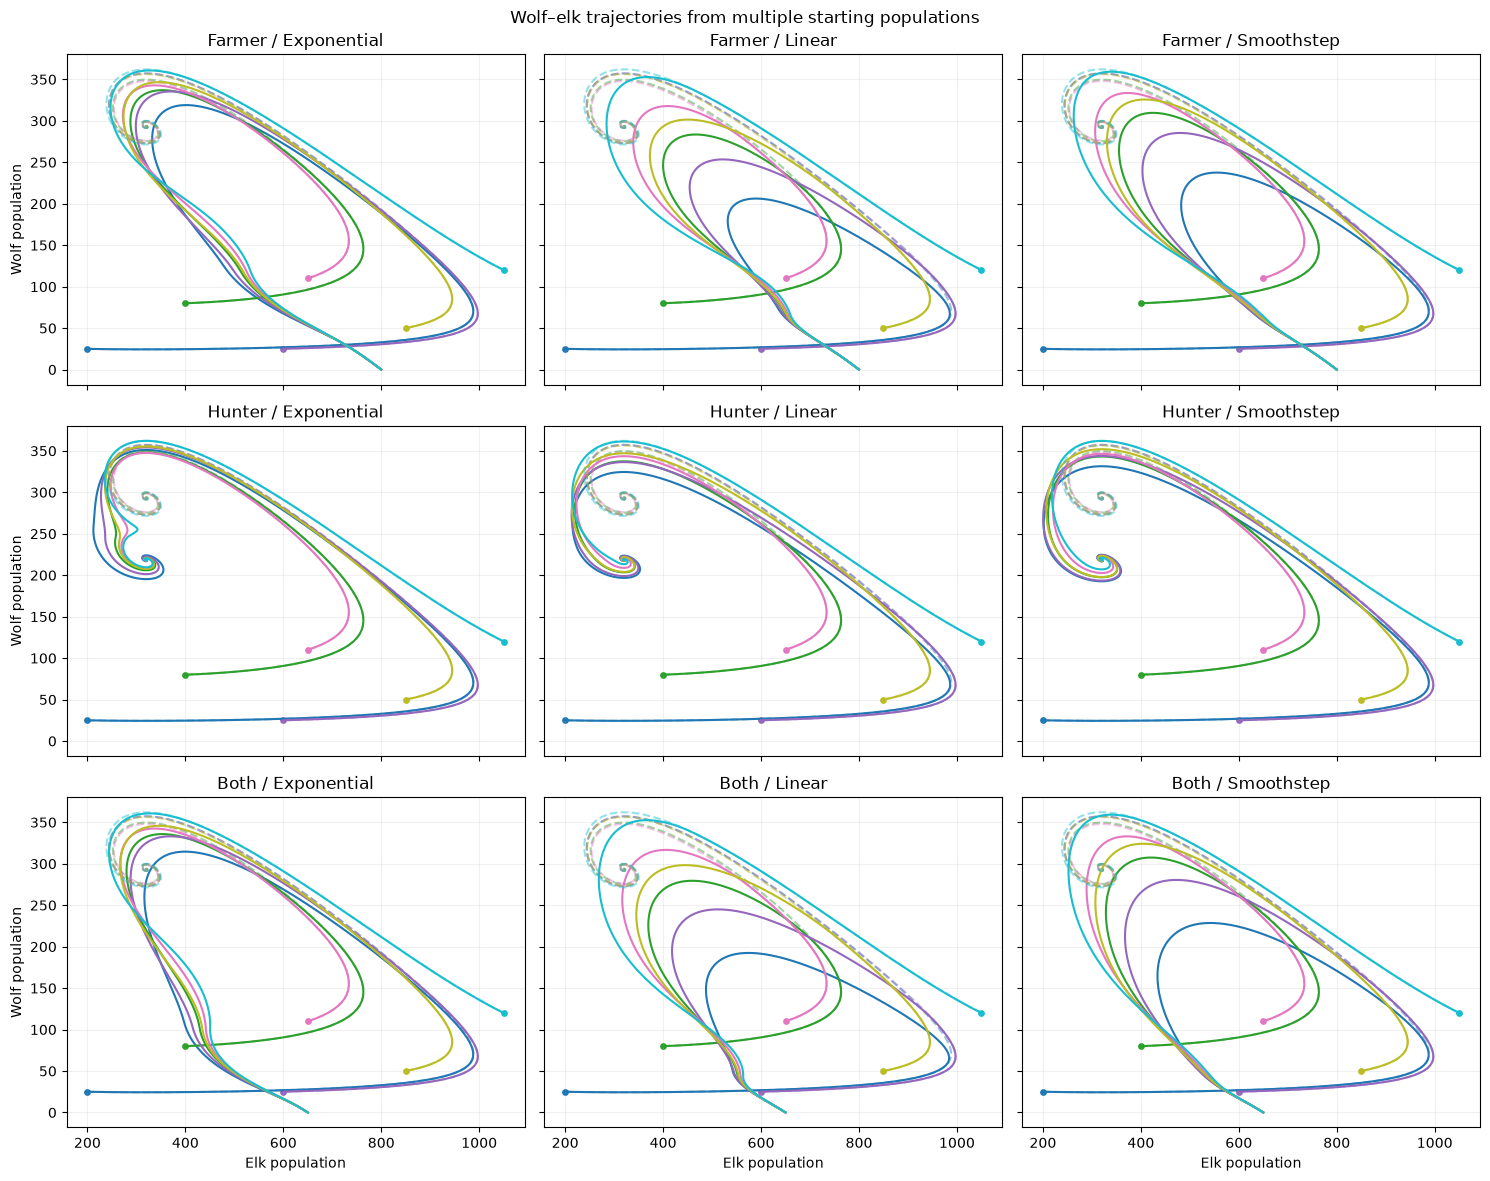

In [4]:
treatments = ('farmer', 'hunter', 'both')
colors = plt.cm.tab10(np.linspace(0, 1, len(INITIAL_STATES)))
controls = {y0: simulate(y0, scenario='control', t_span=(0, T_END), **SETTINGS)
            for y0 in INITIAL_STATES}
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True, sharey=True)
for row, treatment in enumerate(treatments):
    for col, shape in enumerate(SHAPES):
        ax = axes[row, col]
        for color, y0 in zip(colors, INITIAL_STATES):
            base = controls[y0]
            sol = simulate(y0, scenario=treatment, shape=shape,
                           t_span=(0, T_END), **SETTINGS)
            ax.plot(base.y[0], base.y[1], color=color, ls='--', alpha=.45)
            ax.plot(sol.y[0], sol.y[1], color=color, lw=1.5)
            ax.scatter(*y0, color=color, s=15)
        ax.set_title(f'{treatment.title()} / {shape.title()}')
        ax.grid(alpha=.18)
        if row == 2: ax.set_xlabel('Elk population')
        if col == 0: ax.set_ylabel('Wolf population')
fig.suptitle('Wolf–elk trajectories from multiple starting populations')
fig.tight_layout()

## Population versus time

Compare the three introduction shapes against the no-pressure control for one representative starting population.

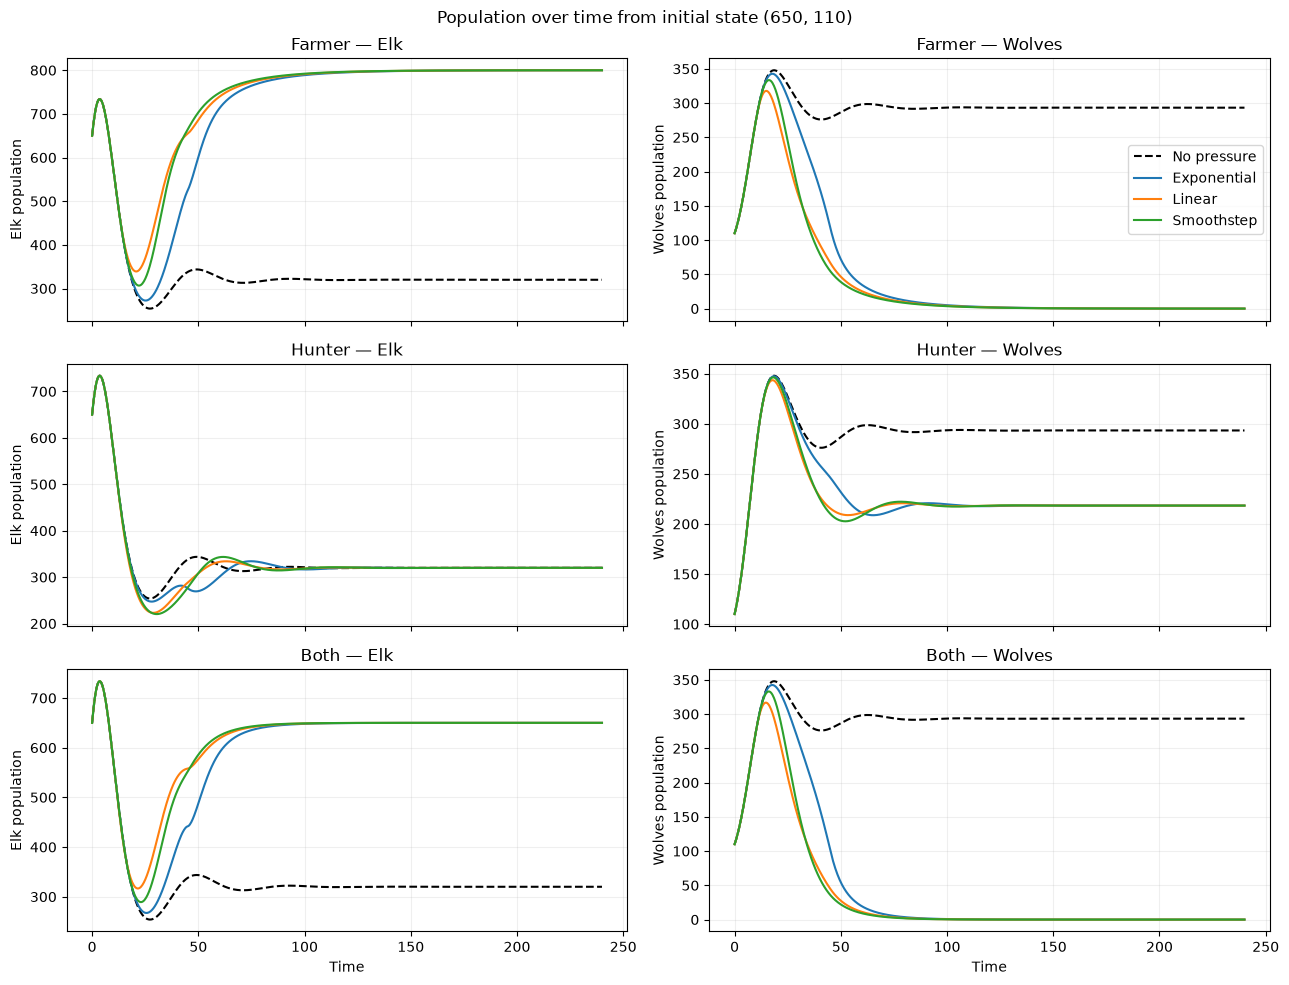

In [5]:
initial = (650, 110)
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
base = simulate(initial, scenario='control', t_span=(0, T_END), **SETTINGS)
for row, treatment in enumerate(treatments):
    for col, (index, species) in enumerate(((0, 'Elk'), (1, 'Wolves'))):
        ax = axes[row, col]
        ax.plot(base.t, base.y[index], color='black', ls='--', label='No pressure')
        for shape in SHAPES:
            sol = simulate(initial, scenario=treatment, shape=shape,
                           t_span=(0, T_END), **SETTINGS)
            ax.plot(sol.t, sol.y[index], label=shape.title())
        ax.set(title=f'{treatment.title()} — {species}', ylabel=f'{species} population')
        ax.grid(alpha=.2)
        if row == 2: ax.set_xlabel('Time')
axes[0, 1].legend()
fig.suptitle(f'Population over time from initial state {initial}')
fig.tight_layout()

## Effect of starting population

Here both pressures follow the smoothstep schedule. Solid lines show the introduction; matching dashed lines show the no-pressure control.

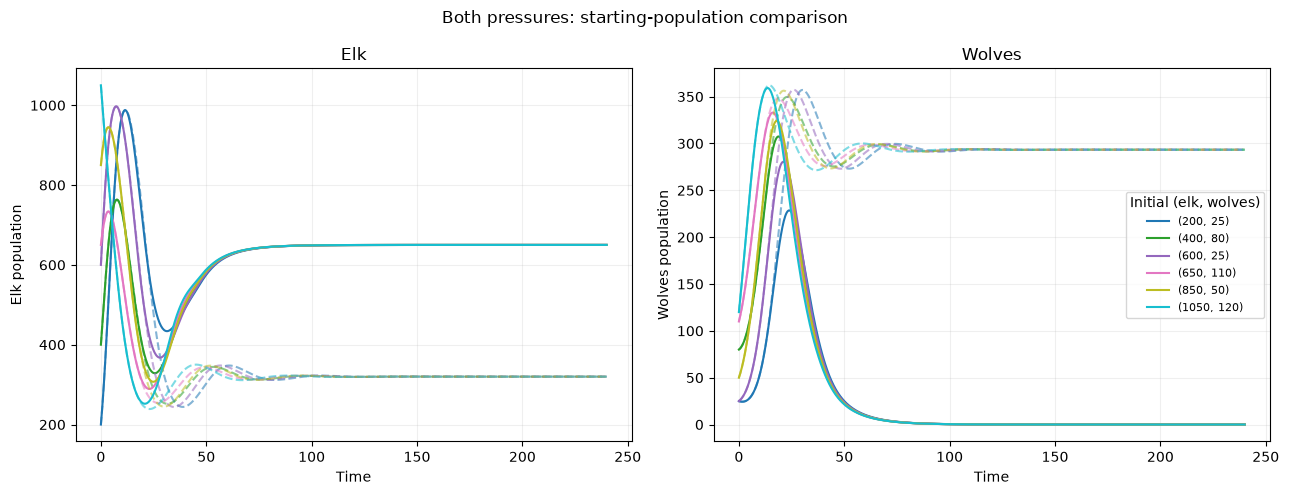

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for color, y0 in zip(colors, INITIAL_STATES):
    base = controls[y0]
    sol = simulate(y0, scenario='both', shape='smoothstep',
                   t_span=(0, T_END), **SETTINGS)
    for index, ax in enumerate(axes):
        ax.plot(base.t, base.y[index], color=color, ls='--', alpha=.55)
        ax.plot(sol.t, sol.y[index], color=color, label=str(y0))
for ax, species in zip(axes, ('Elk', 'Wolves')):
    ax.set(xlabel='Time', ylabel=f'{species} population', title=species)
    ax.grid(alpha=.2)
axes[1].legend(title='Initial (elk, wolves)', fontsize=8)
fig.suptitle('Both pressures: starting-population comparison')
fig.tight_layout()

## Notes

- The equations use continuous populations and illustrative parameters; results are not field predictions.
- During an introduction, pressure changes over time, so phase-plane curves are trajectories through a changing system.
- Farmer pressure changes effective elk capacity to `K - alpha_FE * F(t)` and causes wolf loss through `c_FW * F(t) * W`. Hunter pressure causes elk loss through `c_HE * H(t) * E`.